## Phase 1: Setup, Data Loading & Initial Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv('../data/raw/reviews.csv')

In [2]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

df['score'] = df['score'].astype(int)
df.to_parquet('../data/processed/reviews_clean.parquet', index=False)

(51385, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51385 entries, 0 to 51384
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   platform        51385 non-null  object
 1   review_id       51385 non-null  object
 2   published_date  51385 non-null  object
 3   score           51385 non-null  int64 
 4   review_text     51385 non-null  object
dtypes: int64(1), object(4)
memory usage: 2.0+ MB
None
platform          0
review_id         0
published_date    0
score             0
review_text       0
dtype: int64


### Temuan Phase 1: Kualitas & Struktur Data
* **Volume Data:** Dataset awal memiliki 51.385 baris tanpa baris kosong atau missing values.
* **Optimasi:** Data bersih dikonversi ke format `.parquet` untuk mempercepat proses *loading* di tahap berikutnya.

## Phase 2: Analisis Distribusi Skor & Proporsi Sentimen

=== STATISTIK DESKRIPTIF SKOR ===
Mean (Rata-rata)     : 5.00
Median (Nilai Tengah): 4.0
Mode (Modus)         : 10
Std Dev (Sebaran)    : 4.36
Skewness             : 0.05
Kurtosis             : -1.78


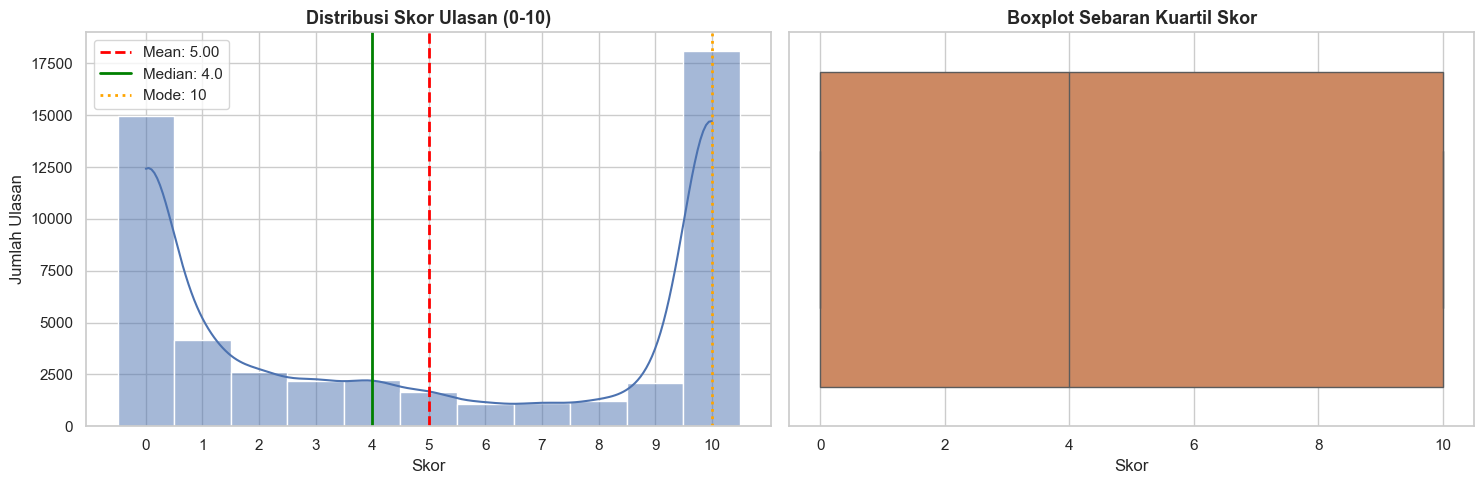

In [3]:
# Membaca data bersih dari Phase 1
df = pd.read_parquet('../data/processed/reviews_clean.parquet')

# Menghitung statistik deskriptif
mean_val = df['score'].mean()
median_val = df['score'].median()
mode_val = df['score'].mode().iloc[0]
std_val = df['score'].std()
skew_val = df['score'].skew()
kurt_val = df['score'].kurt()

print("=== STATISTIK DESKRIPTIF SKOR ===")
print(f"Mean (Rata-rata)     : {mean_val:.2f}")
print(f"Median (Nilai Tengah): {median_val}")
print(f"Mode (Modus)         : {mode_val}")
print(f"Std Dev (Sebaran)    : {std_val:.2f}")
print(f"Skewness             : {skew_val:.2f}")
print(f"Kurtosis             : {kurt_val:.2f}")

# Visualisasi: Histogram + KDE (Kiri) dan Boxplot (Kanan)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gunakan axes[0] untuk plot sebelah kiri
sns.histplot(df['score'], bins=11, kde=True, ax=axes[0], color='#4C72B0', discrete=True)
axes[0].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
axes[0].axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val}')
axes[0].axvline(mode_val, color='orange', linestyle=':', linewidth=2, label=f'Mode: {mode_val}')
axes[0].set_title('Distribusi Skor Ulasan (0-10)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Skor')
axes[0].set_ylabel('Jumlah Ulasan')
axes[0].set_xticks(range(0, 11))
axes[0].legend()

# Gunakan axes[1] untuk plot sebelah kanan
sns.boxplot(x=df['score'], ax=axes[1], color='#DD8452')
axes[1].set_title('Boxplot Sebaran Kuartil Skor', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Skor')

plt.tight_layout()
plt.show()

=== PROPORSI SENTIMEN ===
                 Jumlah Ulasan  Persentase (%)
sentiment_group                               
Negatif (0-3)            23903           46.52
Netral (4-6)              4971            9.67
Positif (7-10)           22511           43.81


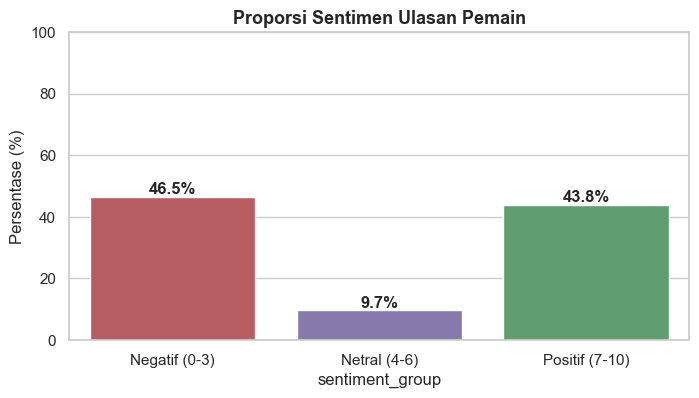

In [4]:
# Mengelompokkan skor ke dalam 3 kategori sentimen
def kelompokkan_sentimen(skor):
    if skor <= 3:
        return 'Negatif (0-3)'
    elif skor <= 6:
        return 'Netral (4-6)'
    else:
        return 'Positif (7-10)'

df['sentiment_group'] = df['score'].apply(kelompokkan_sentimen)

# Menghitung jumlah dan persentase
urutan = ['Negatif (0-3)', 'Netral (4-6)', 'Positif (7-10)']
jumlah = df['sentiment_group'].value_counts().reindex(urutan)
persen = (df['sentiment_group'].value_counts(normalize=True) * 100).reindex(urutan)

ringkasan_sentimen = pd.DataFrame({
    'Jumlah Ulasan': jumlah,
    'Persentase (%)': persen.round(2)
})
print("=== PROPORSI SENTIMEN ===")
print(ringkasan_sentimen)

# Visualisasi Bar Chart Proporsi Sentimen
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=ringkasan_sentimen.index, y=ringkasan_sentimen['Persentase (%)'], hue=ringkasan_sentimen.index, palette=['#C44E52', '#8172B3', '#55A868'], legend=False)
plt.title('Proporsi Sentimen Ulasan Pemain', fontsize=13, fontweight='bold')
plt.ylabel('Persentase (%)')
plt.ylim(0, 100)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontweight='bold')

plt.show()

### Temuan Phase 2: Pola Sebaran Skor & Sentimen
* **Bentuk Distribusi:** Sebaran skor berbentuk **bimodal (menumpuk di 0 dan 10)** dengan modus berada di skor **10** diikuti skor **0**.
* **Ukuran Pemusatan:** Nilai rata-rata (*mean*) adalah **5.00**, sedangkan nilai tengah (*median*) adalah **4.0**. Nilai *skewness* sebesar **0.05** menunjukkan distribusi hampir simetris secara keseluruhan, sementara *kurtosis* sebesar **-1.78** mengonfirmasi bentuk distribusi yang terbelah ekstrem ke dua ujung.
* **Segmentasi Sentimen:** Ulasan terpolarisasi tajam dan didominasi kategori **Negatif (0–3)** sebesar **46.5%**, hampir berimbang dengan **Positif (7–10)** sebesar **43.8%**, sedangkan **Netral (4–6)** hanya **9.7%**.

## Phase 3: Analisis Panjang Ulasan vs Skor

=== RATA-RATA & MEDIAN PANJANG KATA PER SENTIMEN ===
                  mean  median   max
sentiment_group                     
Negatif (0-3)     72.9    39.0  1364
Netral (4-6)     118.3    66.0   972
Positif (7-10)    67.4    35.0   992

Korelasi Skor vs Jumlah Kata: -0.026


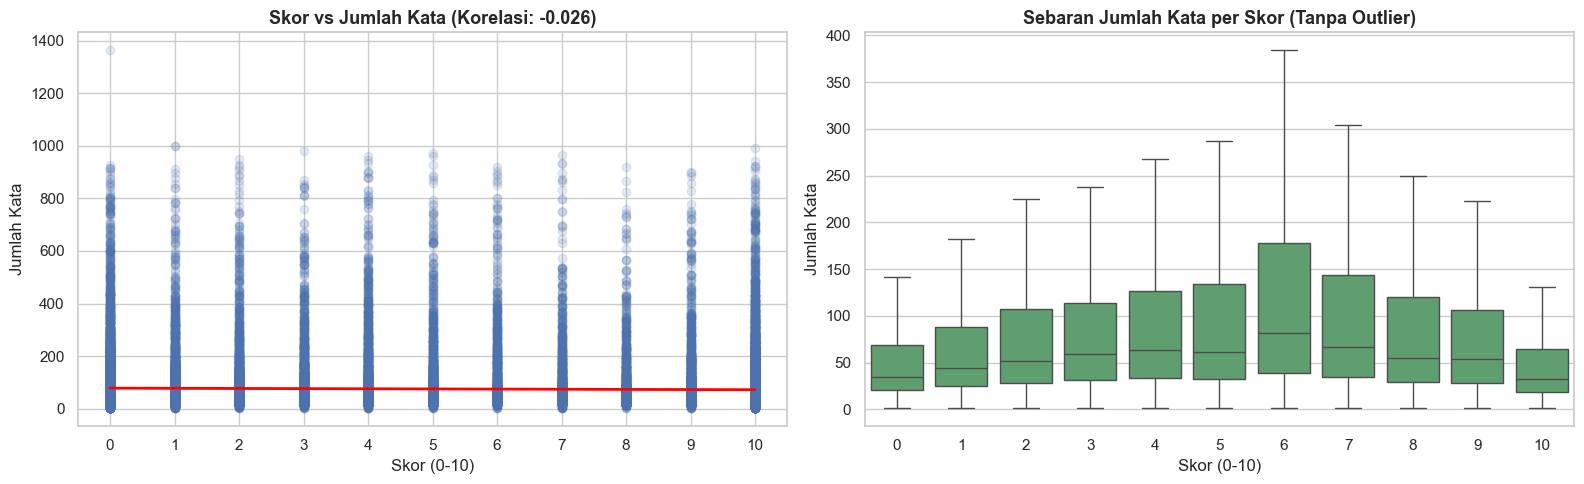

In [6]:
# 1. Membuat kolom jumlah karakter dan jumlah kata
df['text_length'] = df['review_text'].str.len()
df['word_count'] = df['review_text'].str.split().str.len()

# 2. Statistik panjang kata per kelompok sentimen
print("=== RATA-RATA & MEDIAN PANJANG KATA PER SENTIMEN ===")
print(df.groupby('sentiment_group', observed=False)['word_count'].agg(['mean', 'median', 'max']).round(1))

# 3. Menghitung korelasi Pearson antara skor dan jumlah kata
korelasi = df['score'].corr(df['word_count'])
print(f"\nKorelasi Skor vs Jumlah Kata: {korelasi:.3f}")

# 4. Visualisasi: Scatter + Trendline (Kiri) dan Boxplot per Skor (Kanan)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot kiri: Scatter plot dengan garis regresi (menggunakan ax1)
sns.regplot(data=df, x='score', y='word_count', ax=ax1,
            scatter_kws={'alpha': 0.15, 'color': '#4C72B0'},
            line_kws={'color': 'red', 'linewidth': 2})
ax1.set_title(f'Skor vs Jumlah Kata (Korelasi: {korelasi:.3f})', fontsize=13, fontweight='bold')
ax1.set_xlabel('Skor (0-10)')
ax1.set_ylabel('Jumlah Kata')
ax1.set_xticks(range(0, 11))

# Plot kanan: Boxplot panjang kata di tiap skor (menggunakan ax2)
sns.boxplot(data=df, x='score', y='word_count', ax=ax2, showfliers=False, color='#55A868')
ax2.set_title('Sebaran Jumlah Kata per Skor (Tanpa Outlier)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Skor (0-10)')
ax2.set_ylabel('Jumlah Kata')

plt.tight_layout()
plt.show()

### Temuan Phase 3: Hubungan Skor dengan Panjang Ulasan
* **Korelasi Linear Mendekati Nol (`-0.026`):** Tidak ditemukan hubungan linear langsung antara skor dan panjang tulisan karena polanya berbentuk **non-linear**.
* **Pola pada Boxplot:** Ulasan terpanjang justru ditulis oleh kelompok **Netral (4–6)** dengan rata-rata **118.3 kata**.
* **Kutub Ekstrem Cenderung Singkat:** Pemberi skor **Negatif (0–3)** rata-rata hanya menulis **72.9 kata** dan **Positif (7–10)** sebesar **67.4 kata**. Ini menunjukkan skor 0 dan 10 didominasi reaksi emosional singkat, sedangkan skor menengah berisi kritik konstruktif yang lebih terperinci.